<a href="https://colab.research.google.com/github/KishanSadeesh/DataScience/blob/main/NaiveBayes1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

In [51]:
data = pd.read_csv("DataCoSupplyChainDataset.csv", encoding='latin1')
data

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class


In [7]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder

In [19]:
X = data[["Product Price","Sales per customer","Days for shipping (real)"]][:1000]
X

,Product Price,Sales per customer,Days for shipping (real)
0,327.750000,314.640015,3
1,327.750000,311.359985,5
2,327.750000,309.720001,4
3,327.750000,304.809998,3
4,327.750000,298.250000,2
...,...,...,...
995,59.990002,251.960007,3
996,59.990002,251.960007,5
997,59.990002,248.960007,6
998,59.990002,248.960007,5


In [18]:
y = data['Late_delivery_risk'][:1000]
y

,Late_delivery_risk
0,0.0
1,1.0
2,0.0
3,0.0
4,0.0
...,...
995,0.0
996,1.0
997,1.0
998,1.0


In [10]:
data['Late_delivery_risk'] = data['Late_delivery_risk'].fillna(data['Late_delivery_risk'].mean())

In [20]:
y

,Late_delivery_risk
0,0.0
1,1.0
2,0.0
3,0.0
4,0.0
...,...
995,0.0
996,1.0
997,1.0
998,1.0


In [21]:
le = LabelEncoder()

In [22]:
y = le.fit_transform(y)

In [23]:
model = GaussianNB()
model.fit(X, y)

GaussianNB()

In [31]:
y_pred = model.predict(X)


In [26]:
print("Predicted Data: ", le.inverse_transform(prediction)[0])

Predicted Data:  1.0


In [27]:
#Product Price","Sales per customer","Days for shipping (real)
price = float(input("Enter price: "))
sales = float(input("Enter sales: "))
days = float(input("Enter days: "))
print(model.predict([[price,sales,days]]))

Enter price: 399.10
Enter sales: 200.01
Enter days: 2.5
[1]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


In [30]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [32]:
accuracy = accuracy_score(y, y_pred)
accuracy

0.801

In [33]:
precision = precision_score(y, y_pred, average='weighted')
precision

0.8032427836277106

In [34]:

recall=recall_score(y,y_pred,average='weighted')
recall


0.801

In [35]:
f1=f1_score(y,y_pred,average='weighted')
f1


0.8006313673983195

In [36]:
cm=confusion_matrix(y,y_pred)
cm

array([[422,  78],
       [121, 379]])

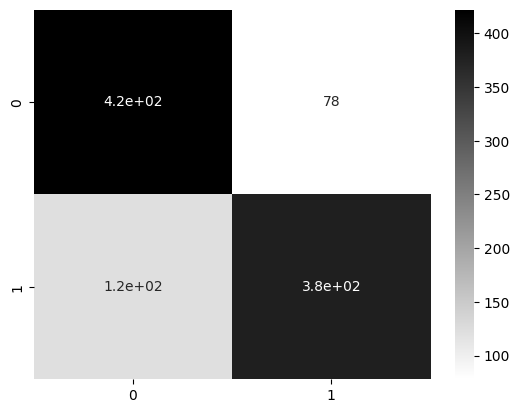

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm,annot=True,cmap="binary")
plt.show()

In [28]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import BernoulliNB

In [41]:
import pandas as pd

df = pd.read_csv("hf://datasets/haoxianc/vstepanenko_disaster-tweets/tweets.csv")
df

,id,keyword,location,text,target
0,0,ablaze,NaN,"Communal violence in Bhainsa, Telangana. ""Ston...",1
1,1,ablaze,NaN,Telangana: Section 144 has been imposed in Bha...,1
2,2,ablaze,New York City,Arsonist sets cars ablaze at dealership https:...,1
3,3,ablaze,"Morgantown, WV",Arsonist sets cars ablaze at dealership https:...,1
4,4,ablaze,NaN,"""Lord Jesus, your love brings freedom and pard...",0
...,...,...,...,...,...
11365,11365,wrecked,Blue State in a red sea,Media should have warned us well in advance. T...,0
11366,11366,wrecked,arohaonces,i feel directly attacked 💀 i consider moonbin ...,0
11367,11367,wrecked,🇵🇭,i feel directly attacked 💀 i consider moonbin ...,0
11368,11368,wrecked,auroraborealis,"ok who remember ""outcast"" nd the ""dora"" au?? T...",0


In [42]:
df['text'].head(10)

,text
0,"Communal violence in Bhainsa, Telangana. ""Ston..."
1,Telangana: Section 144 has been imposed in Bha...
2,Arsonist sets cars ablaze at dealership https:...
3,Arsonist sets cars ablaze at dealership https:...
4,"""Lord Jesus, your love brings freedom and pard..."
5,"If this child was Chinese, this tweet would ha..."
6,Several houses have been set ablaze in Ngemsib...
7,Asansol: A BJP office in Salanpur village was ...
8,"National Security Minister, Kan Dapaah's side ..."
9,This creature who’s soul is no longer clarent ...


In [47]:
vectorizer = CountVectorizer(binary=True,stop_words="english",min_df=2)
X = vectorizer.fit_transform(df["text"].fillna(""))
y = df['target']

In [44]:
model = BernoulliNB()
model.fit(X,y)


BernoulliNB()

In [52]:
# Ensure BernoulliNB is fitted on the disaster tweets text features (X, y)
text_model = BernoulliNB()
text_model.fit(X, y)

text = input("Enter text : ")
y_pred = text_model.predict(vectorizer.transform([text]))
print("Predicted target:", y_pred[0])

Enter text : "There is a massive earthquake in the city"
Predicted target: 0
